# Лабораторная работа 3. 3D диод — самописный решатель

Дрейф-диффузия на Python (`tools/dd3d_ise.py`) с физикой ISE: подвижность Масетти,
насыщение скорости Канали по модулю поля на элементе, сужение запрещённой зоны
OldSlotboom, без рекомбинации — те же модели, что в DEVSIM.

- **Сетка** — тензорная, на осях сетки ISE с дроблением; ячейки контрольных объёмов
  прямоугольные, те же, что у DEVSIM на тензорной сетке.
- **Метод** — итерация Гуммеля: уравнение Пуассона методом Ньютона при замороженных
  квазиуровнях, затем электроны, затем дырки; ускорение Андерсона по квазиуровням.
- **Линейные системы** — прямой решатель: cuDSS на видеокарте или SuperLU на CPU.

Расчёт выполняется скриптом `python/sweep_ise.py` в отдельном процессе. Без `RUN`
используются готовые результаты из `python/`.

In [1]:
import sys, os
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "tools")) and ROOT != "/":
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, os.path.join(ROOT, "tools"))
LAB = os.path.join(ROOT, "Lab3_diode_3D")
sys.path.insert(0, LAB)
import numpy as np
from IPython.display import Image, display

import subprocess

RUN = False        # True — пересчитать, False — взять готовые npz из python/
SPLIT = 2          # деление осей сетки ISE: 1 — 10 тыс. узлов, 2 — 76 тыс.
PYDIR = os.path.join(LAB, "python")

def python_with(module):
    """Интерпретатор, в котором импортируется module: текущий или одно из conda-окружений.
    Проверка — настоящим импортом в отдельном процессе: папка devsim/ рядом с блокнотом
    выглядит для find_spec как пакет."""
    cands = [sys.executable]
    for env in ("nanomod", "TCAD3D"):
        for base in (os.path.expanduser("~/anaconda3"), "/opt/anaconda3", os.path.expanduser("~/miniconda3")):
            cands += [os.path.join(base, "envs", env, exe) for exe in ("bin/python", "python.exe")]
    for exe in cands:
        if os.path.exists(exe) and subprocess.run([exe, "-c", "import " + module], cwd=os.path.expanduser("~"),
                                                  capture_output=True).returncode == 0:
            return exe
    return None

PY = python_with("devsim")          # dd3d_ise берёт константы физики из tools/dev_ise.py
GPU = bool(PY) and subprocess.run([PY, "-c", "import cupy, nvmath"], capture_output=True).returncode == 0
print("интерпретатор:", PY)
print("видеокарта:", "есть (cuDSS)" if GPU else "нет, CPU (SuperLU)")

интерпретатор: /opt/anaconda3/envs/TCAD3D/bin/python
видеокарта: нет, CPU (SuperLU)


In [2]:
# ---- ВАРИАНТ ----
VARIANT = 2
LX, LY, LZ = 1.0, 3.0, 0.8      # мкм: x × y × z, LZ — толщина d
NB  = 1.4e+17                   # бор, сверху, 1/см3
NAs = 1.0e+17                   # мышьяк, снизу, 1/см3
ANODE = {"A": (0, 1, 1, 2), "B": (0.5, 1, 1, 2)}   # (x0, y0, x1, y1), мкм
# -----------------
ZJ = LZ / 2                     # переход посередине по высоте

## 1. Сетка

In [3]:
import dfise, tensor_mesh
v = dfise.read_grid3d(os.path.join(LAB, "ise", "sA_msh.grd"))["vertices"]
xs, ys, zs = (tensor_mesh.refine(v[:, k], SPLIT) for k in range(3))
print("сетка %d × %d × %d = %d узлов" % (len(xs), len(ys), len(zs), len(xs) * len(ys) * len(zs)))
print("минимальный шаг, мкм: x %.4f, y %.4f, z %.4f" % tuple(np.diff(a).min() for a in (xs, ys, zs)))

сетка 41 × 81 × 23 = 76383 узлов
минимальный шаг, мкм: x 0.0050, y 0.0050, z 0.0125


## 2. Расчёт

Ниже 0.8 В Гуммель сходится за 3–5 итераций, на 2–4 В — за 19–36 (без ускорения
Андерсона — 200 итераций без сходимости). На 76 тыс. узлов на TITAN X — 17–90 с на
точку, 11 минут на ВАХ из 14 точек (`--coarse`); на CPU — в 30–100 раз медленнее.

In [4]:
def run(t):
    args = [PY, "-u", os.path.join(PYDIR, "sweep_ise.py"), t, str(SPLIT), "--coarse"] + (["--gpu"] if GPU else [])
    p = subprocess.Popen(args, cwd=PYDIR, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end="")
    return p.wait()

if RUN:
    assert PY, "нет интерпретатора с devsim: conda env create -f environment.yml"
    for t in ANODE:
        run(t)

## 3. Результаты

In [5]:
import json
import json, viz
ref = json.load(open(os.path.join(LAB, "devsim", "reference_iv.json")))

def ise_iv(t):
    d = viz.read_plt(os.path.join(LAB, "ise", "s%s_des.plt" % t))
    return np.asarray(d["Anode OuterVoltage"]), np.abs(np.asarray(d["Anode TotalCurrent"]))

def at(c, v):
    return float(np.interp(v, c[0], c[1]))
def own_iv(t):
    z = np.load(os.path.join(PYDIR, "iv_ise_%s_t%d.npz" % (t, SPLIT)))
    return z["V"], np.abs(z["I"])

rA, rB = np.array(ref["A"]), np.array(ref["B"])
o = {t: own_iv(t) for t in ANODE}; i = {t: ise_iv(t) for t in ANODE}
print("U, В   эталон A  ISE A  свой A   эталон B  ISE B  свой B")
for v in (1.0, 1.5, 2.0, 3.0, 3.95):
    print("%.2f   %.3f     %.3f  %.3f    %.3f     %.3f  %.3f"
          % (v, at(rA, v) * 1e3, at(i["A"], v) * 1e3, at(o["A"], v) * 1e3,
             at(rB, v) * 1e3, at(i["B"], v) * 1e3, at(o["B"], v) * 1e3))
print("B ниже A при 3.95 В: %.1f%%, эталон %.1f%%"
      % ((1 - at(o["B"], 3.95) / at(o["A"], 3.95)) * 100, (1 - at(rB, 3.95) / at(rA, 3.95)) * 100))

U, В   эталон A  ISE A  свой A   эталон B  ISE B  свой B
1.00   0.826     0.890  0.917    0.592     0.636  0.621
1.50   3.009     3.093  3.552    2.029     2.111  2.096
2.00   4.143     4.211  4.597    2.679     2.735  2.531
3.00   5.033     5.102  5.072    3.111     3.161  2.727
3.95   5.300     5.391  5.211    3.250     3.303  2.799
B ниже A при 3.95 В: 46.3%, эталон 38.7%


## 4. Иллюстрации

Ячейки прямоугольные, поэтому структура нарисована «кирпичами».

самописный решатель (76383 узлов): A 0.00522 А, B 0.00280 А при 4 В


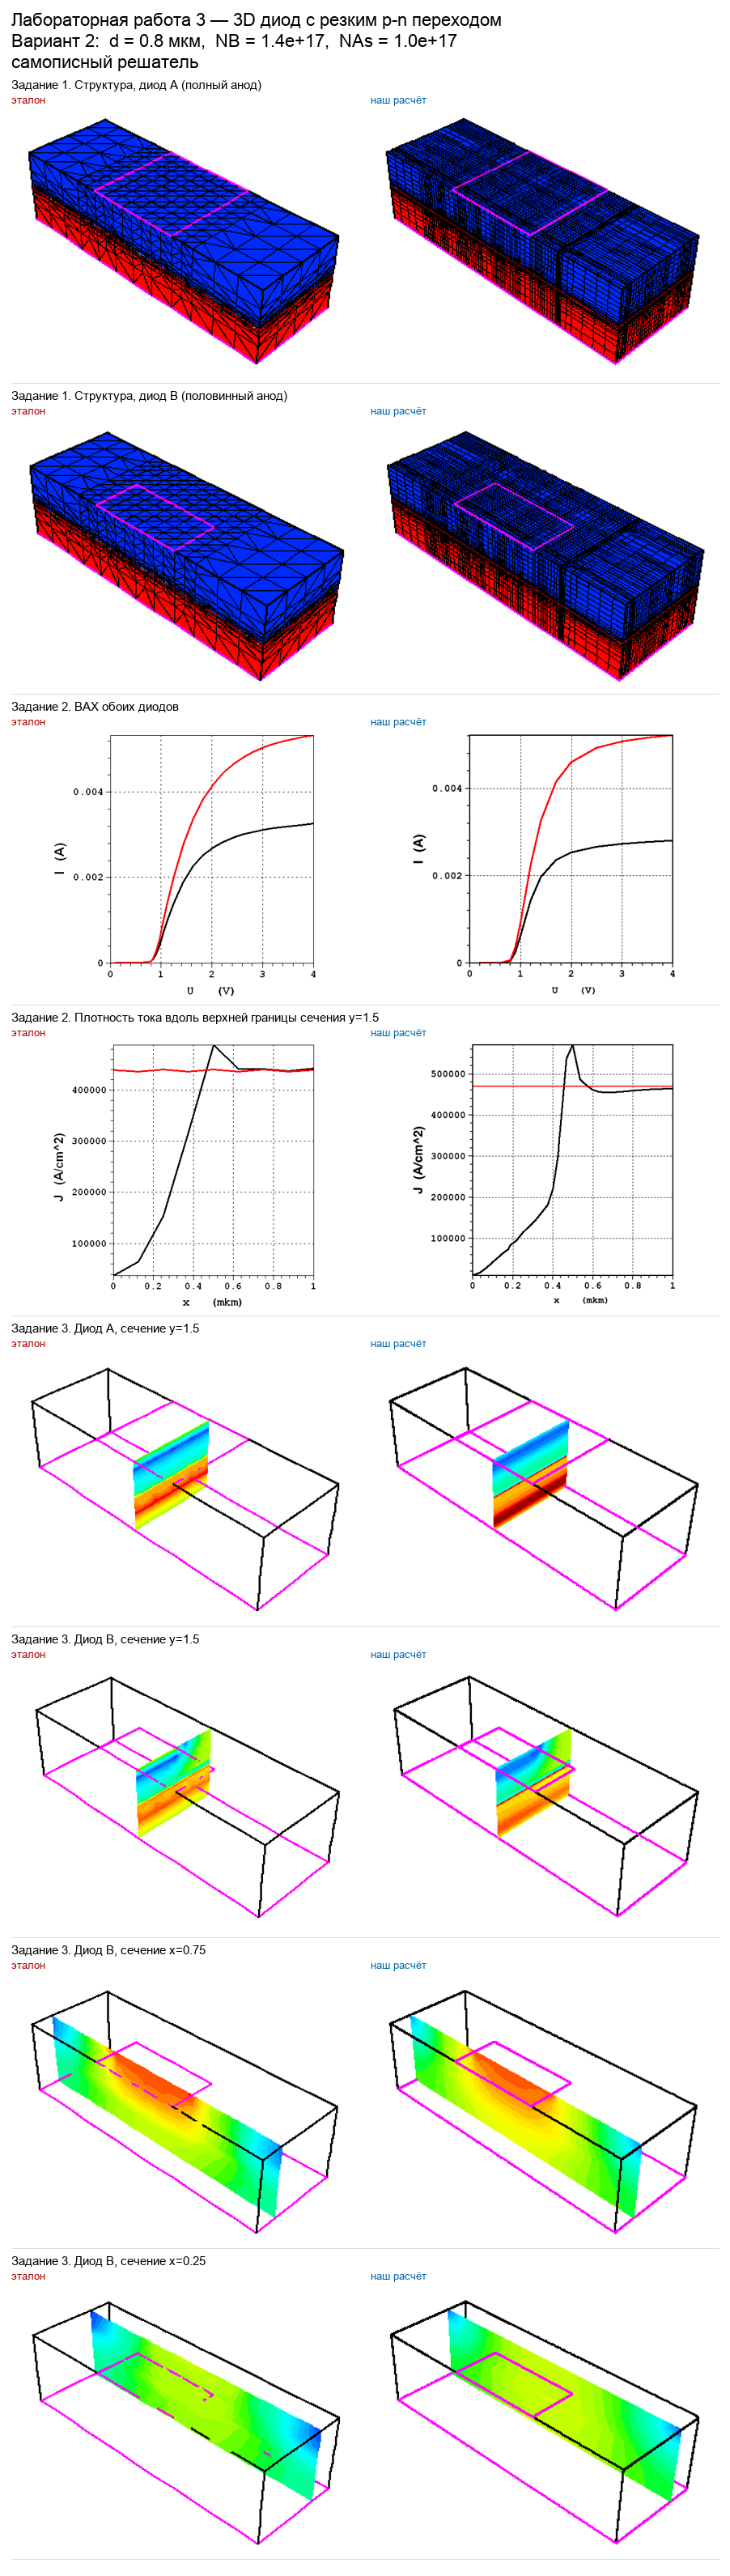

In [6]:
import make_figures as mf
if SPLIT == 2:
    mf.figures_python()
    mf.sheets()
display(Image(os.path.join(LAB, "results", "python", "СВОДНЫЙ_ЛИСТ.png")))

### Вывод

_(сравнение с ISE и DEVSIM, сходимость по сетке)_